# EDA разметки BDD100K

Атрибуты кадров, undefined, сочетания и набор запросов для оценки.
Картинки смотрю только из train_sub: val и test остаются для финальных метрик.

In [1]:
import sys
sys.path.insert(0, "..")

import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, data, queries

plt.rcParams.update({"font.size": 12, "figure.dpi": 100})
frames = data.load_frames()
frames.groupby(["split", "part"]).size().unstack(fill_value=0)

part,eval,train,train_sub
split,,,
test,20000,0,0
train,0,40000,30000
val,10000,0,0


## 0. Разметка против архива картинок

Разметка - `bdd100k_labels.zip`, в нём свой JSON на каждый кадр (`100k/{train,val,test}/<имя>.json`).
Проверяю по каждому сплиту: JSON столько же, сколько картинок в `bdd100k_images_100k.zip`, имена совпадают,
у каждого JSON есть weather, scene и timeofday. Рамки объектов считаю, чтобы понять, откуда разметка у test.

In [2]:
check = data.check_labels(frames, data.image_members())
assert data.labels_ok(check)
check

,ожидается,json,картинок,имена_совпадают,json_без_атрибута,кадров_с_объектами,кадров_с_box2d,box2d_на_кадр
split,,,,,,,,
train,70000,70000,70000,True,0,70000,70000,18.4
val,10000,10000,10000,True,0,10000,10000,18.6
test,20000,20000,20000,True,0,20000,20000,18.4


Всё сходится. У всех 20 000 кадров test есть рамки box2d, в среднем 18,4 на кадр, как в train и val.
То есть test в этом архиве размечен полностью, а не только атрибутами кадра.

## 1. Распределения атрибутов

In [3]:
dist = pd.concat({a: frames.groupby("split")[a].value_counts(normalize=True).unstack(0) for a in config.ATTRS})
dist = dist[["train", "val", "test"]].round(3)
dist

split                    train    val   test
weather   clear          0.534  0.535  0.538
          foggy          0.002  0.001  0.002
          overcast       0.125  0.124  0.128
          partly cloudy  0.070  0.074  0.072
          rainy          0.073  0.074  0.065
          snowy          0.080  0.077  0.078
          undefined      0.116  0.116  0.117
scene     city street    0.623  0.611  0.614
          gas stations   0.000  0.001  0.000
          highway        0.249  0.250  0.253
          parking lot    0.005  0.005  0.005
          residential    0.116  0.125  0.119
          tunnel         0.002  0.003  0.002
          undefined      0.005  0.005  0.005
timeofday dawn/dusk      0.072  0.078  0.074
          daytime        0.526  0.526  0.522
          night          0.400  0.393  0.402
          undefined      0.002  0.004  0.002

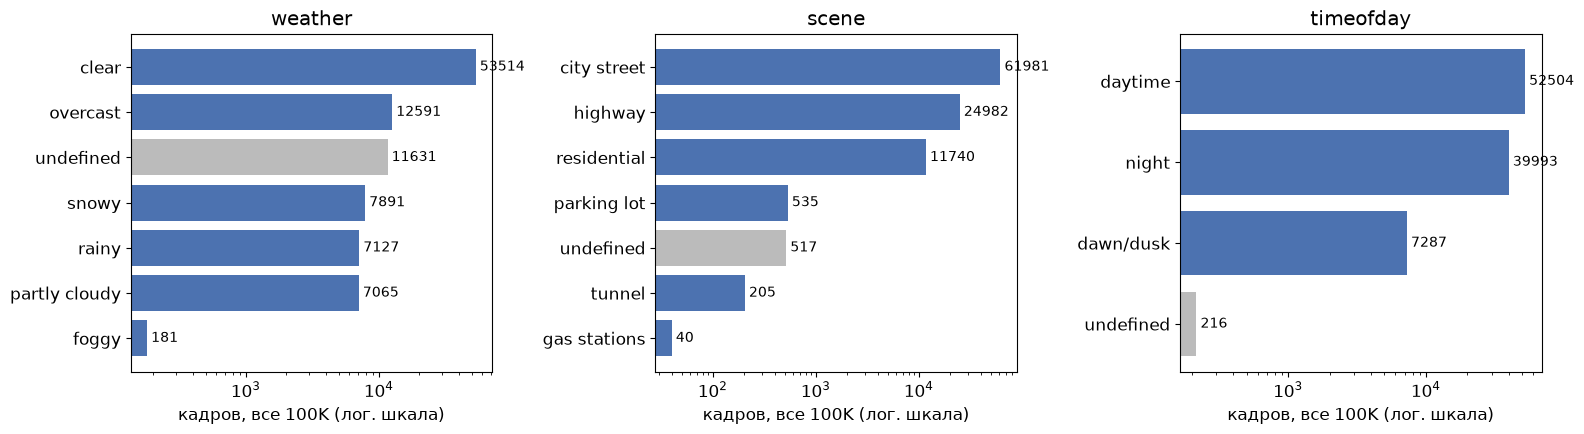

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, a in zip(axes, config.ATTRS):
    s = frames[a].value_counts()
    ax.barh(s.index[::-1], s.values[::-1], color=["#bbbbbb" if v == config.UNDEFINED else "#4c72b0" for v in s.index[::-1]])
    ax.set_xscale("log")
    ax.set_title(a)
    ax.set_xlabel("кадров, все 100K (лог. шкала)")
    for y, v in enumerate(s.values[::-1]):
        ax.text(v, y, f" {v}", va="center", fontsize=10)
fig.tight_layout()
fig.savefig(config.RESULTS / "eda_attributes.png", dpi=150)

Распределения в train, val и test почти одинаковые. Дисбаланс сильный: clear, city street и daytime - большинство,
а foggy (0,2%), tunnel (0,2%) и gas stations (меньше 0,1%) - единицы на тысячу кадров.

## 2. Кто такие undefined

In [5]:
und = frames[config.ATTRS] == config.UNDEFINED
pd.DataFrame({"доля undefined": und.mean().round(4), "кадров": und.sum()})

,доля undefined,кадров
weather,0.1163,11631
scene,0.0052,517
timeofday,0.0022,216


In [6]:
# какие кадры остаются без погоды: доли по сцене и времени суток
d = frames[frames.part != "eval"]
by_scene = pd.crosstab(d.scene, d.weather == config.UNDEFINED, normalize="index")[True].rename("weather=undefined")
by_time = pd.crosstab(d.timeofday, d.weather == config.UNDEFINED, normalize="index")[True].rename("weather=undefined")
pd.concat([by_scene, by_time]).round(3).to_frame()

,weather=undefined
city street,0.129
gas stations,0.074
highway,0.061
parking lot,0.159
residential,0.142
tunnel,0.884
undefined,0.281
dawn/dusk,0.105
daytime,0.191
night,0.016


Погода undefined не случайна: у 88% туннелей погоды нет, в туннеле её не видно. Днём погода undefined у 19% кадров,
ночью у 2%. Если выкинуть из галереи все кадры хоть с одним undefined, пропадёт 12% кадров, а от туннелей в eval
останется 8 из 76. Поэтому галерея своя у каждого запроса: выкидываю только кадры с undefined в атрибутах этого запроса
(`config.GALLERY = "per_query"`).

In [7]:
qs = queries.all_queries()
ev = frames[frames.part == "eval"]
strict = queries.count_relevant(ev, qs, "strict")
per_query = queries.count_relevant(ev, qs, "per_query")
cmp = pd.DataFrame({"query_id": qs.query_id, "relevant_strict": strict.n_relevant, "gallery_strict": strict.n_gallery,
                    "relevant_per_query": per_query.n_relevant, "gallery_per_query": per_query.n_gallery})
cmp[qs.n_attrs == 1]

,query_id,relevant_strict,gallery_strict,relevant_per_query,gallery_per_query
0,weather=clear,16023,26383,16102,26503
1,weather=overcast,3804,26383,3807,26503
2,weather=partly cloudy,2178,26383,2179,26503
3,weather=rainy,2015,26383,2044,26503
4,weather=snowy,2314,26383,2320,26503
5,weather=foggy,49,26383,51,26503
6,scene=city street,15983,26383,18400,29849
7,scene=highway,7160,26383,7568,29849
8,scene=residential,3088,26383,3635,29849
9,scene=parking lot,132,26383,157,29849


## 3. Сочетания атрибутов

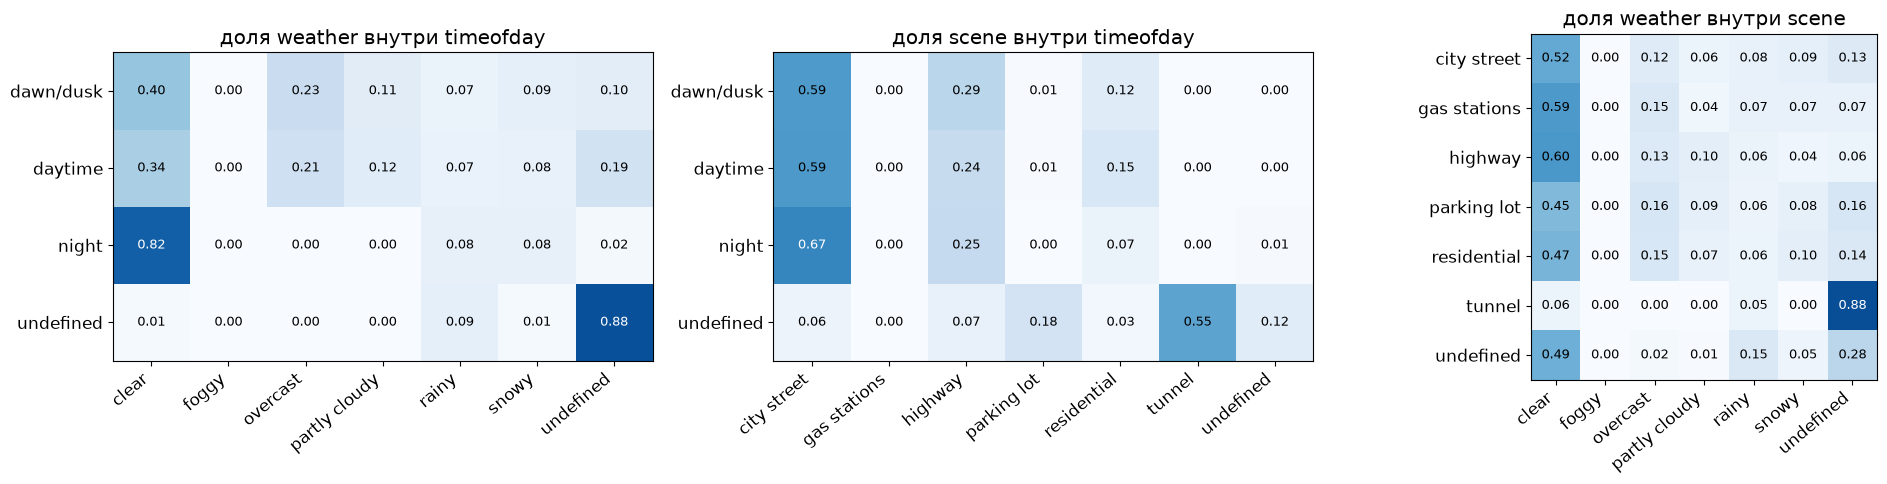

In [8]:
d = frames[frames.part != "eval"]
pairs = [("timeofday", "weather"), ("timeofday", "scene"), ("scene", "weather")]
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (r, c) in zip(axes, pairs):
    t = pd.crosstab(d[r], d[c], normalize="index")
    im = ax.imshow(t.values, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(t.shape[1]), t.columns, rotation=40, ha="right")
    ax.set_yticks(range(t.shape[0]), t.index)
    ax.set_title(f"доля {c} внутри {r}")
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.values[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if t.values[i, j] > 0.6 else "black")
fig.tight_layout()
fig.savefig(config.RESULTS / "eda_cooccurrence.png", dpi=150)

Ночью 82% кадров размечены как clear, а overcast и partly cloudy почти не встречаются (0,3% и 0,2% против 21% и 12% днём).
Облака ночью не видно, поэтому clear ночью значит скорее "без осадков", чем "ясное небо". Для промптов это важно:
"clear sky" может не подойти ночным кадрам с меткой clear. Проверю на train_sub в этапе 2.

## 4. Как выглядят классы

По 5 случайных кадров из train_sub на каждое значение. Картинки сохраняю в `artifacts/` и в репозиторий не кладу:
лицензию на сами данные BDD100K ещё надо проверить на сайте.

In [9]:
rng = np.random.default_rng(config.SEED)
sub = frames[frames.part == "train_sub"]
N_EX = 5


def grid(attr, path):
    values = queries.VALUES[attr] + [config.UNDEFINED]
    fig, axes = plt.subplots(len(values), N_EX, figsize=(N_EX * 3.2, len(values) * 1.95))
    with zipfile.ZipFile(config.IMAGES_ZIP) as z:
        for i, v in enumerate(values):
            rows = sub[sub[attr] == v]
            rows = rows.iloc[rng.choice(len(rows), min(N_EX, len(rows)), replace=False)]
            for j in range(N_EX):
                ax = axes[i, j]
                ax.axis("off")
                if j < len(rows):
                    r = rows.iloc[j]
                    ax.imshow(data.read_image(z, r.split, r["name"]).resize((320, 180)))
                    other = [r[a] for a in config.ATTRS if a != attr]
                    ax.set_title(" / ".join(other), fontsize=8)
            axes[i, 0].text(-20, 90, v, ha="right", va="center", fontsize=12)
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)


grid("weather", config.ARTIFACTS / "eda_examples_weather.png")

In [10]:
grid("scene", config.ARTIFACTS / "eda_examples_scene.png")

In [11]:
grid("timeofday", config.ARTIFACTS / "eda_examples_timeofday.png")

Что видно на примерах (это 5 кадров на значение, не статистика):
- snowy - чаще снег на обочинах при ясном небе, а не снегопад;
- tunnel - часто проезд под эстакадой, а не настоящий туннель;
- foggy - половина примеров ночью, туман от засветки не отличить;
- ночные кадры очень тёмные, сцену по ним видно плохо;
- почти на всех кадрах видны капот и приборная панель.

Отсюда ожидания для этапа 2: метки шумные, и промпт "snowy road" может работать лучше "snowing".

## 5. Запросы и порог

In [12]:
counts = queries.count_both(frames)
counts.groupby("n_attrs").agg(запросов=("query_id", "size"),
                              без_релевантных_в_eval=("n_relevant_eval", lambda x: (x == 0).sum()),
                              медиана_релевантных_eval=("n_relevant_eval", "median"))

,запросов,без_релевантных_в_eval,медиана_релевантных_eval
n_attrs,,,
1,15,0,2320.0
2,72,7,169.5
3,108,32,5.0


In [13]:
queries.threshold_table(counts)

,1_атр,2_атр,3_атр,всего
порог,,,,
1,15,63,68,146
10,15,51,46,112
20,14,45,41,100
30,14,41,35,90
50,14,39,33,86
100,12,37,28,77
200,11,34,21,66


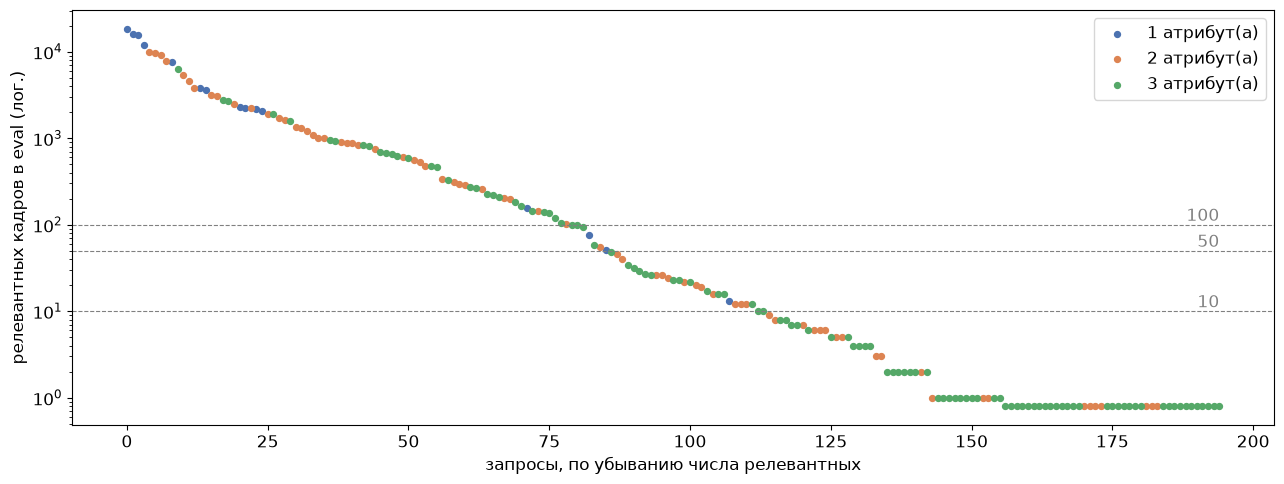

In [14]:
fig, ax = plt.subplots(figsize=(13, 5))
colors = {1: "#4c72b0", 2: "#dd8452", 3: "#55a868"}
c = counts.sort_values("n_relevant_eval", ascending=False).reset_index(drop=True)
for n in (1, 2, 3):
    m = c.n_attrs == n
    ax.scatter(c.index[m], c.n_relevant_eval[m].clip(lower=0.8), s=18, color=colors[n], label=f"{n} атрибут(а)")
ax.set_yscale("log")
for t in (10, 50, 100):
    ax.axhline(t, color="grey", lw=0.8, ls="--")
    ax.text(len(c) - 1, t, f" {t}", va="bottom", ha="right", color="grey")
ax.set_xlabel("запросы, по убыванию числа релевантных")
ax.set_ylabel("релевантных кадров в eval (лог.)")
ax.legend()
fig.tight_layout()
fig.savefig(config.RESULTS / "eda_query_counts.png", dpi=150)

Из 195 сочетаний у 39 в eval нет ни одного релевантного кадра (например, snowy + tunnel), ещё у 21 их один-два.
Сверху - до 18 тысяч. Число запросов на каждом пороге - в `results/threshold_counts.csv`: на порогах 10 / 50 / 100 / 200
остаётся 112 / 86 / 77 / 66, плато нет. Порог 50 выбран по одной причине: на нём P@50 может дойти до 1 у каждого запроса.

In [15]:
chosen = queries.select(counts)
print(len(chosen), "запросов")
chosen.groupby("n_attrs").agg(запросов=("query_id", "size"),
                              мин_доля=("prevalence_eval", "min"),
                              медиана_доли=("prevalence_eval", "median"),
                              макс_доля=("prevalence_eval", "max")).round(4)

86 запросов


,запросов,мин_доля,медиана_доли,макс_доля
n_attrs,,,,
1,14,0.0019,0.1047,0.6164
2,39,0.0021,0.0381,0.3733
3,33,0.0022,0.0125,0.2422


In [16]:
# значения атрибутов, которые попали хоть в один запрос
{a: sorted(chosen[a].dropna().unique()) for a in config.ATTRS}

{'weather': ['clear', 'foggy', 'overcast', 'partly cloudy', 'rainy', 'snowy'],
 'scene': ['city street', 'highway', 'parking lot', 'residential', 'tunnel'],
 'timeofday': ['dawn/dusk', 'daytime', 'night']}

In [17]:
dropped_single = counts[(counts.n_attrs == 1) & ~counts.query_id.isin(chosen.query_id)]
dropped_single[["query_id", "n_relevant_eval", "n_relevant_train_sub"]]

,query_id,n_relevant_eval,n_relevant_train_sub
11,scene=gas stations,13,10
